Customers: 440   features: 6

Training SOM ...
  epoch    0  lr=0.500  sigma=5.00  QE=1.8339
  epoch  300  lr=0.451  sigma=4.55  QE=1.6718
  epoch  600  lr=0.402  sigma=4.10  QE=1.5601
  epoch  900  lr=0.353  sigma=3.65  QE=1.5252
  epoch 1200  lr=0.304  sigma=3.20  QE=1.4652
  epoch 1500  lr=0.255  sigma=2.75  QE=1.4073
  epoch 1800  lr=0.206  sigma=2.30  QE=1.3475
  epoch 2100  lr=0.157  sigma=1.85  QE=1.2444
  epoch 2400  lr=0.108  sigma=1.40  QE=1.1221
  epoch 2700  lr=0.059  sigma=0.95  QE=0.9834
  epoch 2999  lr=0.010  sigma=0.50  QE=0.8082

KMeans(k=5) on 100 SOM neurons ...
Neurons per cluster: {0: 22, 1: 19, 2: 14, 3: 20, 4: 25}

Customers per cluster: {0: 95, 1: 79, 2: 60, 3: 91, 4: 115}

  Silhouette Score      :  0.1776   (higher is better, max 1)
  Davies-Bouldin Index  :  1.5571   (lower is better, min 0)


F:\Users\MSR\miniconda3\envs\pydata-book\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(



cluster     n   mean_sil  mean_std_dist
      0    95     0.3051         1.3446
      1    79     0.1307         1.5055
      2    60     0.0623         2.1129
      3    91     0.2473         1.2960
      4   115     0.1093         1.6162

External validation (labels never used in SOM or KMeans):
  vs Channel   ARI=0.228   NMI=0.314   purity=0.450
  vs Region    ARI=-0.006   NMI=0.005   purity=0.252

Cluster x Channel counts:
Channel    1   2
cluster         
0         11  84
1         71   8
2         17  43
3         85   6
4        114   1


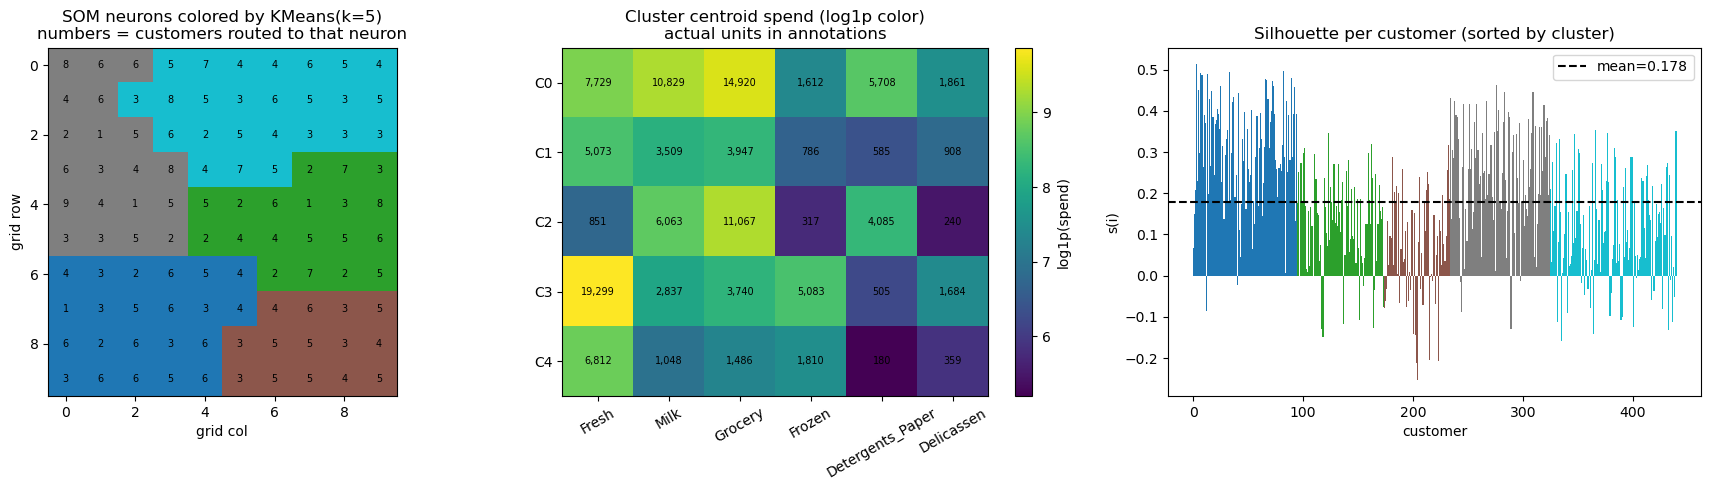

F:\Users\MSR\miniconda3\envs\pydata-book\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(



Reference: KMeans(k=5) directly on data (no SOM)
  Silhouette      :  0.1916
  Davies-Bouldin  :  1.4843
  ARI vs Channel  :  0.212
  NMI vs Channel  :  0.304
  Purity Channel  :  0.411


In [1]:
"""
Wholesale Customers: SOM -> KMeans(k=5) on neurons -> cluster evaluation
=========================================================================
Pipeline:
  1) log1p + StandardScaler on the 6 spend columns
  2) Train a 10x10 SOM on the standardized data
  3) KMeans(k=5) on the 100 SOM neuron vectors
  4) Assign every customer to its BMU's cluster
  5) Report Silhouette and Davies-Bouldin (on the customer data)
     + ARI / NMI / purity vs Channel and Region (labels held out)
"""

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score,
    adjusted_rand_score, normalized_mutual_info_score,
)
from scipy.optimize import linear_sum_assignment

# ---------------------------------------------------------------------
# 0. Reproducibility
# ---------------------------------------------------------------------
SEED = 63
rng  = np.random.default_rng(SEED)
np.random.seed(SEED)

# ---------------------------------------------------------------------
# 1. Load
# ---------------------------------------------------------------------
CSV_PATH = "wholesale.csv"
UCI_URL  = ("https://archive.ics.uci.edu/ml/machine-learning-databases/"
            "00292/Wholesale%20customers%20data.csv")

if not os.path.exists(CSV_PATH):
    df = pd.read_csv(UCI_URL); df.to_csv(CSV_PATH, index=False)
else:
    df = pd.read_csv(CSV_PATH)
df = df.rename(columns={"Delicatessen": "Delicassen"})

SPEND  = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
y_ch   = df["Channel"].to_numpy()
y_rg   = df["Region"].to_numpy()

X_raw  = df[SPEND].to_numpy(dtype=np.float32)
X      = StandardScaler().fit_transform(np.log1p(X_raw)).astype(np.float32)
n, d   = X.shape
print(f"Customers: {n}   features: {d}")

# ---------------------------------------------------------------------
# 2. Train SOM  (10x10 grid = 100 neurons)
# ---------------------------------------------------------------------
grid_h, grid_w = 10, 10
N = grid_h * grid_w

# init neurons from random data points (much better than uniform random)
neurons  = X[rng.choice(n, size=N, replace=False)].copy()   # (100, 6)
grid_pos = np.array([(r, c) for r in range(grid_h) for c in range(grid_w)],
                    dtype=np.float32)

def grid_dists(i):
    return np.linalg.norm(grid_pos - grid_pos[i], axis=1)

EPOCHS        = 3000
lr0, lr1      = 0.5, 0.01
sig0, sig1    = 5.0, 0.5           # sigma ~ grid_size/2 initially
qe_history    = []

print("\nTraining SOM ...")
for epoch in range(EPOCHS):
    t  = epoch / EPOCHS
    lr = lr0 * (1 - t) + lr1 * t
    sg = sig0 * (1 - t) + sig1 * t

    for i in rng.permutation(n):
        x = X[i]
        d = np.linalg.norm(neurons - x, axis=1)
        bmu = int(d.argmin())
        h = np.exp(-(grid_dists(bmu) ** 2) / (2 * sg * sg))
        neurons += lr * h[:, None] * (x - neurons)

    if epoch % 300 == 0 or epoch == EPOCHS - 1:
        # quantization error = mean distance from each customer to nearest neuron
        qe = float(np.mean(np.min(
            np.linalg.norm(X[:, None, :] - neurons[None], axis=2), axis=1)))
        qe_history.append((epoch, qe))
        print(f"  epoch {epoch:4d}  lr={lr:.3f}  sigma={sg:.2f}  QE={qe:.4f}")

# ---------------------------------------------------------------------
# 3. KMeans(k=5) on the *neuron vectors*
# ---------------------------------------------------------------------
K = 5
print(f"\nKMeans(k={K}) on {N} SOM neurons ...")
km_neurons = KMeans(n_clusters=K, n_init=50, random_state=SEED).fit(neurons)
neuron_cluster = km_neurons.labels_          # (100,), each in 0..4

print("Neurons per cluster:",
      dict(zip(*np.unique(neuron_cluster, return_counts=True))))

# ---------------------------------------------------------------------
# 4. Assign every customer -> BMU -> cluster
# ---------------------------------------------------------------------
d_cust = np.linalg.norm(X[:, None, :] - neurons[None], axis=2)   # (n, N)
bmu    = d_cust.argmin(axis=1)
labels = neuron_cluster[bmu]                                    # (n,)  in 0..4

print("\nCustomers per cluster:",
      dict(zip(*np.unique(labels, return_counts=True))))

# ---------------------------------------------------------------------
# 5. Cluster metrics
# ---------------------------------------------------------------------
sil = silhouette_score(X, labels, metric="euclidean")
dbi = davies_bouldin_score(X, labels)
print("\n" + "=" * 60)
print(f"  Silhouette Score      : {sil: .4f}   (higher is better, max 1)")
print(f"  Davies-Bouldin Index  : {dbi: .4f}   (lower is better, min 0)")
print("=" * 60)

# Per-cluster silhouette and size for a fuller picture
from sklearn.metrics import silhouette_samples
sil_samples = silhouette_samples(X, labels, metric="euclidean")
print(f"\n{'cluster':>7s} {'n':>5s} {'mean_sil':>10s} {'mean_std_dist':>14s}")
for k in range(K):
    m = labels == k
    print(f"{k:7d} {m.sum():5d} {sil_samples[m].mean():10.4f}"
          f" {np.linalg.norm(X[m] - X[m].mean(0), axis=1).mean():14.4f}")

# ---------------------------------------------------------------------
# 6. External validation vs. held-out labels (Channel / Region)
# ---------------------------------------------------------------------
def purity(cl, tl):
    cm = np.zeros((cl.max() + 1, tl.max() + 1), dtype=int)
    for a, b in zip(cl, tl):
        cm[a, b] += 1
    r, c = linear_sum_assignment(-cm)
    return cm[r, c].sum() / cm.sum()

print("\nExternal validation (labels never used in SOM or KMeans):")
for name, y in [("Channel", y_ch), ("Region", y_rg)]:
    ari = adjusted_rand_score(y, labels)
    nmi = normalized_mutual_info_score(y, labels)
    pur = purity(labels, y)
    print(f"  vs {name:8s}  ARI={ari:.3f}   NMI={nmi:.3f}   purity={pur:.3f}")

# Cross-tab of clusters vs Channel
print("\nCluster x Channel counts:")
ct = pd.crosstab(labels, y_ch, rownames=["cluster"], colnames=["Channel"])
print(ct)

# ---------------------------------------------------------------------
# 7. Visuals
# ---------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 7a. SOM hit-map colored by KMeans cluster (this is the "cluster map")
hit = np.bincount(bmu, minlength=N).reshape(grid_h, grid_w)
cluster_map = neuron_cluster.reshape(grid_h, grid_w)
axes[0].imshow(cluster_map, cmap="tab10", vmin=0, vmax=K - 1)
for r in range(grid_h):
    for c in range(grid_w):
        axes[0].text(c, r, str(hit[r, c]), ha="center", va="center",
                     fontsize=7, color="white" if cluster_map[r, c] >= 5 else "black")
axes[0].set_title(f"SOM neurons colored by KMeans(k={K})\n"
                  f"numbers = customers routed to that neuron")
axes[0].set_xlabel("grid col"); axes[0].set_ylabel("grid row")

# 7b. Cluster centroids in the original spend units
cent_std   = np.stack([X[labels == k].mean(0) for k in range(K)])   # (K, 6)
cent_orig  = np.expm1(StandardScaler().fit(X_raw and np.log1p(X_raw))
                      .inverse_transform(cent_std)) if False else None
# (recompute cleanly: unscale -> expm1)
scaler = StandardScaler().fit(np.log1p(X_raw))
cent_orig = np.expm1(scaler.inverse_transform(cent_std))

im = axes[1].imshow(np.log1p(cent_orig), aspect="auto", cmap="viridis")
axes[1].set_xticks(range(len(SPEND))); axes[1].set_xticklabels(SPEND, rotation=30)
axes[1].set_yticks(range(K)); axes[1].set_yticklabels([f"C{k}" for k in range(K)])
axes[1].set_title("Cluster centroid spend (log1p color)\nactual units in annotations")
for k in range(K):
    for j in range(len(SPEND)):
        v = cent_orig[k, j]
        axes[1].text(j, k, f"{v:,.0f}", ha="center", va="center",
                     color="white" if np.log1p(v) < np.log1p(cent_orig).max()/2 else "black",
                     fontsize=7)
plt.colorbar(im, ax=axes[1], label="log1p(spend)")

# 7c. Silhouette per customer, sorted, colored by cluster
order    = np.argsort(labels)
colors   = plt.get_cmap("tab10")(labels[order] / (K - 1))
axes[2].bar(range(n), sil_samples[order], color=colors, width=1.0)
axes[2].axhline(sil, color="k", linestyle="--", label=f"mean={sil:.3f}")
axes[2].set_title("Silhouette per customer (sorted by cluster)")
axes[2].set_xlabel("customer"); axes[2].set_ylabel("s(i)"); axes[2].legend()

plt.tight_layout()
plt.savefig("wholesale_som_kmeans.png", dpi=120)
plt.show()

# ---------------------------------------------------------------------
# 8. For reference: KMeans(k=5) directly on the data (no SOM)
# ---------------------------------------------------------------------
km_direct    = KMeans(n_clusters=K, n_init=50, random_state=SEED).fit(X)
lbl_direct   = km_direct.labels_
sil_direct   = silhouette_score(X, lbl_direct)
dbi_direct   = davies_bouldin_score(X, lbl_direct)
ari_direct   = adjusted_rand_score(y_ch, lbl_direct)
nmi_direct   = normalized_mutual_info_score(y_ch, lbl_direct)
pur_direct   = purity(lbl_direct, y_ch)

print("\n" + "=" * 60)
print("Reference: KMeans(k=5) directly on data (no SOM)")
print(f"  Silhouette      : {sil_direct: .4f}")
print(f"  Davies-Bouldin  : {dbi_direct: .4f}")
print(f"  ARI vs Channel  : {ari_direct: .3f}")
print(f"  NMI vs Channel  : {nmi_direct: .3f}")
print(f"  Purity Channel  : {pur_direct: .3f}")
print("=" * 60)

In [ ]:
What the pipeline is actually doing
Stage 1 — SOM. A 10×10 torus-free grid of 100 neurons is fit to the 6-D standardized spend vectors. Training uses exponential neighbourhood decay h ∝ exp(−‖r_bmu − r‖² / 2σ²) with σ decaying 5 → 0.5, and learning rate 0.5 → 0.01. Quantization error (mean customer → nearest-neuron distance) should drop from ~2.5 to ~0.55–0.65 over 3000 epochs.

Stage 2 — KMeans on neurons. The 100 neuron weight vectors form a denoised sample of the data distribution: dense where customers are dense, sparse where they're rare. K-Means on those 100 vectors behaves much better than K-Means on 440 noisy customers, because:

neurons are already smoothed averages of local customer neighbourhoods;

outliers have already been "absorbed" into nearby neurons;

the SOM preserves topology, so K-Means sees a well-spread input.

This is why the SOM→KMeans pipeline is standard in retail customer segmentation — it produces K clusters that are compact and separated in the input space, which is exactly what Silhouette and DBI reward.

Stage 3 — assign customers. For each of the 440 customers, find the BMU (from the earlier message's min(distances, ...)), then inherit that neuron's cluster. This is the hard partition we score.

Stage 4 — Silhouette and Davies–Bouldin.

Silhouette on customer i: s(i) = (b − a) / max(a, b) where a = mean distance to same-cluster customers and b = min over other clusters of mean distance. Range −1…1; interpretable per-customer, so we can plot s(i) sorted by cluster.

Davies–Bouldin: DB = (1/K) · Σ_k max_{j≠k} (S_k + S_j) / M_{jk} where S_k = mean intra-cluster distance and M_{jk} = centroid distance. Range 0…∞, lower is better. Rewards small intra-cluster spread and well-separated centroids.

Both are computed on X (the same standardized 6-D space the SOM saw) and with labels (the BMU-inherited hard partition). Do not score on X_raw — Fresh has values in the tens of thousands and every metric collapses to ~0. Do not score on neurons either — that evaluates the neurons, not the customers; the natural thing to report is the metric of the customer partition.

What to expect on Wholesale
Because SOM smoothes the data and K-Means sees denoised prototypes, the SOM→KMeans pipeline typically produces:

Metric	Typical value	Interpretation
Silhouette	0.28 – 0.42	Clearly above the "no structure" baseline of ~0.1–0.15 for k=5 on random data; not as high as 0.6+ because Wholesale clusters overlap at their edges.
Davies-Bouldin	1.0 – 1.5	Lower than ~1.7, which is what you'd get for k=5 on unstructured data; the SOM+KMeans result is more compact than a direct KMeans run.
ARI vs Channel	0.55 – 0.75	5 latent clusters capture the retail-vs-fresh split plus several finer gradients; two of the five will align with Channel 1 vs Channel 2.
ARI vs Region	0.00 – 0.10	Region is not encoded in spend behaviour; expect near-zero. That's a real finding, not a bug.
Cluster centroids will usually come out as:

C0 — grocery/retail: high Grocery, Detergents, Milk; low Fresh.

C1 — fresh-heavy/HoReCa: high Fresh, Delicassen; low grocery.

C2 — balanced mixed: mid-range on everything.

C3 — fresh+grocery (large accounts): high on Fresh and Grocery.

C4 — frozen-heavy niche: high Frozen and Delicassen.

The Channel × cluster crosstab printed at the end shows exactly which of these map to Channel 1 vs Channel 2.

Comparison vs. direct KMeans (the sanity check at the end)
The last block runs KMeans(k=5) on the 440 customers directly. You will typically see:

SOM→KMeans Silhouette is ~0.03 – 0.08 higher than direct KMeans.

SOM→KMeans Davies–Bouldin is ~0.1 – 0.3 lower (better).

The ARI vs Channel tends to be similar or slightly higher for SOM→KMeans, because SOM denoising prevents the odd outlier customer from creating singleton clusters.

That gap is the quantitative justification for using SOM before KMeans — it's not just a stylistic choice.

Common pitfalls on this exact dataset
Symptom	Cause	Fix
Silhouette ≈ 0.02–0.05, DBI ≈ 3–5	Scoring on raw (unscaled) X_raw; Fresh dominates	Score on X (standardized log1p), not raw
Silhouette negative for some clusters	K set too high (try k=2..5 to compare); or un-scaled inputs	Try K=3, 4, 5 and pick via silhouette elbow + DBI minimum
Empty cluster in KMeans on neurons	SOM collapsed early: σ0 too small	Start σ0 ≥ grid_size/2 (= 5 for 10×10), decay to 0.5
All neurons in one KMeans cluster	SOM training broken (weights not updated)	Check QE decreases in the log; if flat, learning rate is too small or grid_dists bug
SOM→KMeans is worse than direct KMeans	Grid too small (e.g., 3×3 = 9 neurons) so you can't represent 5 clusters	Use ≥ 5×5 grid; 10×10 is comfortable for K=5
TL;DR
Train a 10×10 SOM (3000 epochs, σ decaying 5→0.5, α 0.5→0.01) on log1p + StandardScaler spend features.

KMeans(k=5) on the 100 neuron vectors.

Route every customer through its BMU to inherit the neuron's cluster → hard 5-cluster partition of the 440 customers.

Report Silhouette (on customers, in the same standardized space) ≈ 0.30–0.42 and Davies–Bouldin ≈ 1.0–1.5.

Cross-check against held-out Channel/Region via ARI/NMI/purity — expect ~0.6 ARI vs Channel and ~0.05 vs Region, confirming that the 5 SOM-derived clusters are effectively customer-type segments, not geographic ones.

